Exemple of pipeline of the Disco dataset. 

Please refer to tiny_Disco.zip data set and run the bash script first

# Preprocessing

Before starting, we prepare the MCM and the streamlines

### Compute MCM

From the DWI, compute and MCM, here with one isotropic compartment to model free water and 3 anisotropics.

The MCM is already computed but you might be interested by computing a different one. Note that in this case you will probably need to change several line of codes

### Compute DTI and FA
From the DWI, compute the DTI and the FA. 
DTI is in .nii.gz for dipy loader and FA in .nrrd for TractOT

### Compute bundle mask
From the streamlines of the Disco dataset, compute the bundle masks for tracts call 'i', 'q' and 'r'. Also compute the start and the end of the this bundles. 

Then compute the mask of the interestion of these 3 bundles.

### Convert the 'q' tract in vtk
Convert trk streamlines in vtk

### Compute colinear image
From the MCM, compute a colinear mask that indicates which anisotropic compartment is the most colinear to the bundle 'q'.

### Resample streamlines
Resample the streamlines of 'q' to have 10 points unformly distributed.

### Apply injury
Simulate a ill subject by simulating injuries over the MCM over a given mask for the most colinear compartment.

We apply the following modification of the healthy MCM:

- Isotropification:
For each voxel, compute a point of the (OT) geodesic between the covariates and an isotropic covariate with eigenvalue the highest eigenvalue of the original covariate. Hyperparameter is $t\in [0,1]$

- Colinear to free water:
Transfer weight of the most colinear compartment to the free water compartment. Hyperparameter $w_1 \in [0,1]$

- Reduced signal:
Scale uniformly the eigenvalue of the most colinear compartment.  Hyperparameter $l_1 \in [1,+\infty[$

- Colinear to isotropification:
Transfer weight of the most colinear compartment to a new compartment that is isotropic with eigenvalue the highest eigenvalue of the original covariate.  Hyperparameter $w_2 \in [0,1]$

- Colinear to reduced signal:
Transfer weight of the most colinear compartment to a new compartment that is similar to the original but with eigenvalues uniformly scale.  Hyperparameter $w_3 \in [0,1]$ and $l_2 \in [1,+\infty[$


### MCM to DWI to DTI to FA

Simulate the DWI of the ill patient from its MCM and then compute DTI and FA from this DWI.

In this example we use the same set of streamline for the healthy and ill patient. You might be interesting in computing a new set for the ill patient. This can be done by i) computing peaks of the ill-DWI, with mrtrix for example ii) build the Tract Orientation Mapping, using compute_TOM.py iii) perform tractography 'à la Tractseg', using compute_streamline.py. In practice we observe no big differences between recomputed streamlines and original streamlines.

### add FA  and MAS on streamlines

Build Mixture Augmented Streamlines (MAS) and Scalar Augmented Streamlines (SAS)

### Compute cores SAS and MAS of the ill and the healthy patient

When MAS and SAS are built, we compute the cores augmented streamlines 

In [1]:
path='/home/gui/Documents/Post-doc/data/tiny_Disco/'

In [12]:
import numpy as np
import matplotlib.pylab as pl
from dipy.io.streamline import load_tractogram,save_tractogram

from tractot.load_to_numpy import trx_to_numpy_SAT_array,trx_to_numpy_MAT_array,trx_to_numpy_SAT_list,trx_to_numpy_MAT_list
from tractot.build_cores import infer_labels_svm_endpoint, average_SAS_per_labels,average_MAS_per_labels
from tractot.distances import distance_coresSAS_svm,distance_coresMAS_svm

L=5
k_SAS=1
k_MAS=None

SUBJECTS=['100','200']

In [4]:
# Compute the cores SAS
for SUBJECT in SUBJECTS:
    SAS=load_tractogram(path+SUBJECT+'/06-AugmentedTractsOT/6augmented_FA_nolift_q_n10.trx',reference='same',bbox_valid_check=False)
    m,FA,_=trx_to_numpy_SAT_array(SAS)
    
    labels_svm,labels_clus=infer_labels_svm_endpoint(None,L,m,random_state=0)
    cores_m,cores_w,cores_FA,idx_svm,idx_cluster,size_cluster=average_SAS_per_labels(L,m,FA,labels_svm,labels_clus,k=k_SAS) 
    
    cores=SAS.from_sft(cores_m,SAS)
    dico={}
    dico['weights']=cores_w
    dico['scalar']=cores_FA
    dico['svm']=idx_svm
    dico['cluster']=idx_cluster
    dico['size cluster']=size_cluster
    cores.data_per_point=dico
    save_tractogram(cores,path+SUBJECT+'/06-AugmentedTractsOT/7cores_FA_nolift_q_L'+str(L)+'_k'+str(k_SAS)+'.trx',bbox_valid_check=False)

Infer label with index
kmeans over  (535, 3)  endpoints
l =  0 : 1 2 3 4 5 6 7 8 9 10 
l =  1 : 1 2 3 4 5 6 7 8 9 10 
l =  2 : 1 2 3 4 5 6 7 8 9 10 
l =  3 : 1 2 3 4 5 6 7 8 9 10 
l =  4 : 1 2 3 4 5 6 7 8 9 10 
[2026-10-29 15:14:37][dipy] WARNING: Data_per_point has been modified.
Infer label with index
kmeans over  (535, 3)  endpoints
l =  0 : 1 2 3 4 5 6 7 8 9 10 
l =  1 : 1 2 3 4 5 6 7 8 9 10 
l =  2 : 1 2 3 4 5 6 7 8 9 10 
l =  3 : 1 2 3 4 5 6 7 8 9 10 
l =  4 : 1 2 3 4 5 6 7 8 9 10 
[2026-10-29 15:14:38][dipy] WARNING: Data_per_point has been modified.


In [5]:
# Compute the cores MAS
for SUBJECT in SUBJECTS:
    MAS=load_tractogram(path+SUBJECT+'/06-AugmentedTractsOT/6augmented_MAS_nolift_q_n10.trx',reference='same',bbox_valid_check=False)
    m,wI,I,w,S,conf,_=trx_to_numpy_MAT_array(MAS)
    
    labels_svm,labels_clus=infer_labels_svm_endpoint(None,L,m,random_state=0)
    cores_m,cores_wI,cores_I,cores_w,cores_S,idx_svm,idx_cluster,size_cluster=average_MAS_per_labels(L,m,wI,I,w,S,conf,labels_svm,labels_clus,k2=k_MAS) 
    
    cores=MAS.from_sft(cores_m,MAS)
    dico={}
    dico['weight iso']=cores_wI
    dico['iso']=cores_I
    dico['weights aniso']=cores_w
    dico['aniso']=cores_S
    dico['svm']=idx_svm
    dico['cluster']=idx_cluster
    dico['size cluster']=size_cluster
    cores.data_per_point=dico
    save_tractogram(cores,path+SUBJECT+'/06-AugmentedTractsOT/7cores_MAS_nolift_q_L'+str(L)+'_k'+str(k_MAS)+'.trx',bbox_valid_check=False)

Infer label with index
kmeans over  (535, 3)  endpoints
l =  0 : 1 2 3 4 5 6 7 8 9 10 
l =  1 : 1 2 3 4 5 6 7 8 9 10 
l =  2 : 1 2 3 4 5 6 7 8 9 10 
l =  3 : 1 2 3 4 5 6 7 8 9 10 
l =  4 : 1 2 3 4 5 6 7 8 9 10 
[2026-10-29 15:14:42][dipy] WARNING: Data_per_point has been modified.
Infer label with index
kmeans over  (535, 3)  endpoints
l =  0 : 1 2 3 4 5 6 7 8 9 10 
l =  1 : 1 2 3 4 5 6 7 8 9 10 
l =  2 : 1 2 3 4 5 6 7 8 9 10 
l =  3 : 1 2 3 4 5 6 7 8 9 10 
l =  4 : 1 2 3 4 5 6 7 8 9 10 
[2026-10-29 15:14:54][dipy] WARNING: Data_per_point has been modified.


# Compute a distance between the cores 

To conclude this example, we compute a distance between the cores augmented streamlines of the healthy and the ill subject.

In [23]:
#Cores SAS

SAS_healthy=load_tractogram(path+'100/06-AugmentedTractsOT/7cores_FA_nolift_q_L'+str(L)+'_k'+str(k_SAS)+'.trx',reference='same',bbox_valid_check=False)
SAS_ill=load_tractogram(path+'200/06-AugmentedTractsOT/7cores_FA_nolift_q_L'+str(L)+'_k'+str(k_SAS)+'.trx',reference='same',bbox_valid_check=False)

m1,w1,FA1,labels_svm1,_=trx_to_numpy_SAT_list(SAS_healthy)
m2,w2,FA2,labels_svm2,_=trx_to_numpy_SAT_list(SAS_ill)
cost,profile_SAS,idx_SAS,_=distance_coresSAS_svm(m1,m2,w1,w2,FA1,FA2,labels_svm1,labels_svm2,alpha=0,beta=1,sum_or_max='sum')
print(cost)

0.0002538135090479999


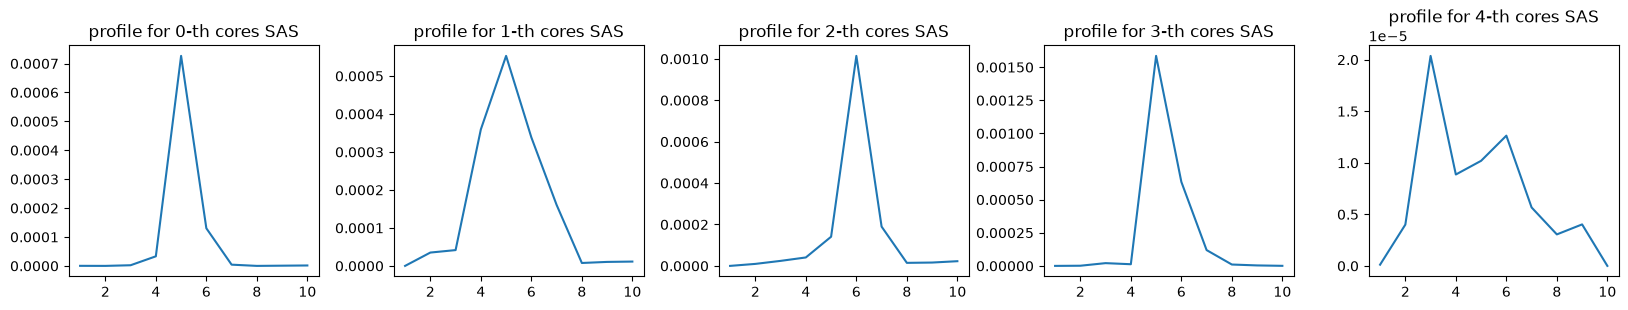

In [25]:
pl.figure(figsize=(20,3))
grid = pl.GridSpec(1,L, wspace=0.3, hspace=0)
for i in range(L):
    pl.subplot(grid[0,i])
    pl.title("profile for "+str(i)+"-th cores SAS")
    pl.plot(idx_SAS[i],profile_SAS[i])        

In [26]:
MAS_healthy=load_tractogram(path+'100/06-AugmentedTractsOT/7cores_MAS_nolift_q_L'+str(L)+'_k'+str(k_MAS)+'.trx',reference='same',bbox_valid_check=False)
MAS_ill=load_tractogram(path+'200/06-AugmentedTractsOT/7cores_MAS_nolift_q_L'+str(L)+'_k'+str(k_MAS)+'.trx',reference='same',bbox_valid_check=False)

m1,wI1,I1,w1,S1,labels_svm1,_=trx_to_numpy_MAT_list(MAS_healthy)
m2,wI2,I2,w2,S2,labels_svm2,_=trx_to_numpy_MAT_list(MAS_ill)
cost,profile_MAS,idx_MAS,_=distance_coresMAS_svm(m1,m2,wI1,wI2,I1,I2,w1,w2,S1,S2,labels_svm1,labels_svm2,alpha=0,beta=1,sum_or_max='sum')


print(cost)

9.270847358306439e-06


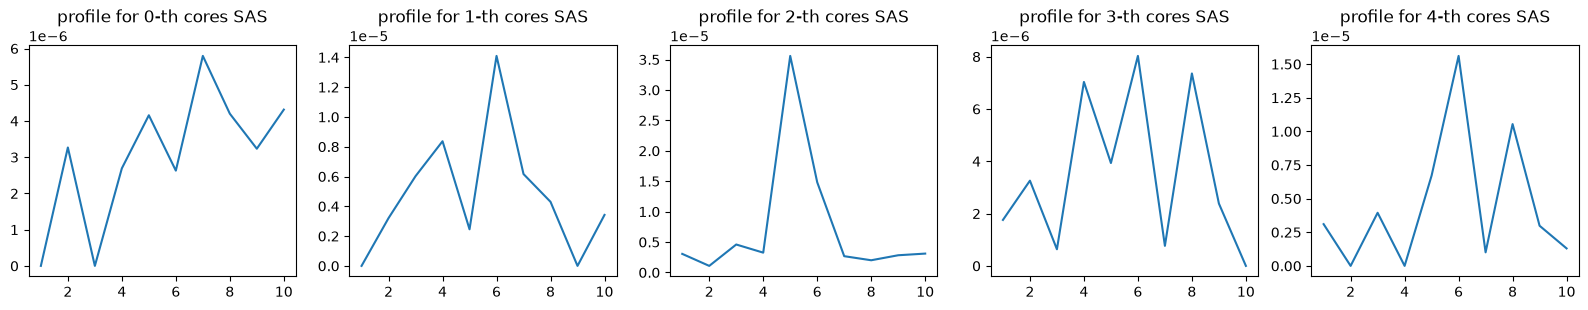

In [27]:
pl.figure(figsize=(20,3))
grid = pl.GridSpec(1,L, wspace=0.2, hspace=0)
for i in range(L):
    pl.subplot(grid[0,i])
    pl.title("profile for "+str(i)+"-th cores SAS")
    pl.plot(idx_MAS[i],profile_MAS[i])        

# Simulate a cohort of healthy and ill and analyze the matrices of distance

In practice, it can be intresting to simulate a cohort of healthy and ill subjects. This can be done by adding a bit of noise on the ill and the healthy MCM. This can be done by running add_noise_mcm.py

Then, we can compute pairwise distances matrices between cores augmented streamlines. One for the cores SAS and another for the cores MAS.

We then validate the superioty of MAS over SAS by hiding some labels of the subjects and try to predict them with the matrices distance.

In the following, we load such matrix that we already computed. 

For this example we use noise with value 7e-4, 2e-5 and 3e-4. We alterate the healthy subject with $w_1=w_2=0, w_3=0.05, l_1=1, l_2=3$ and $t=0$.

In [9]:
import pandas as pd
from matplotlib.lines import Line2D
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.manifold import MDS

In [5]:
#Load matrices of distance
list_d=['healthy','ill']
list_subjects=[
    ['101','102','103','104','105','106','107','108','109','110','111','112','113','114','115','116','117','118','119','120','121','122','123','124','125','126','127','128','129','130'],
    ['201','202','203','204','205','206','207','208','209','210','211','212','213','214','215','216','217','218','219','220','221','222','223','224','225','226','227','228','229','230']
    ]

names=['FA','MAS']


list_lensum=[0]
for i in range(len(list_subjects)):
    list_lensum+=[list_lensum[i]+len(list_subjects[i])]

#Load matrices distance
M=np.zeros((len(names),list_lensum[-1],list_lensum[-1]))
for k,name in enumerate(names):
    for i in range(len(list_d)):
        for j in range(i,len(list_d)):
            M_temp=pd.read_csv(path+'matrices_distance/'+name+'_'+list_d[i]+'_vs_'+list_d[j]+'.csv',index_col=0)
            M_temp.index = M_temp.index.astype(str)
            M_temp.columns = M_temp.columns.astype(str)
            M[k,list_lensum[i]:list_lensum[i+1],list_lensum[j]:list_lensum[j+1]]= M_temp.loc[list_subjects[i],list_subjects[j]]
            if i!=j:
                M[k,list_lensum[j]:list_lensum[j+1],list_lensum[i]:list_lensum[i+1]]= M_temp.loc[list_subjects[i],list_subjects[j]].T
print(M.shape)

(2, 60, 60)


In [7]:
#Visualisation of the matrices

X=np.zeros((len(names),list_lensum[-1],2))

for i in range(len(names)):
    embedding = MDS(n_components=2, n_init=10,metric="precomputed",init="random")
    X[i] = embedding.fit_transform(M[i])

print(X.shape)

(2, 60, 2)


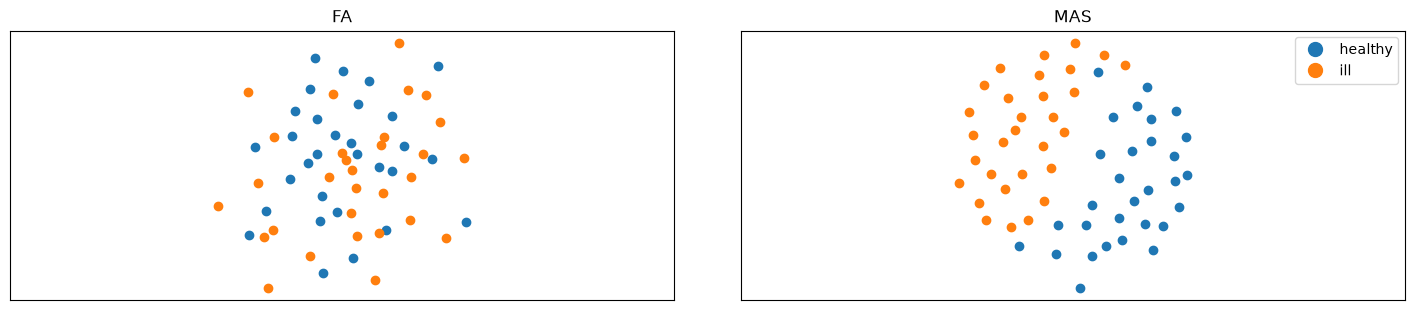

In [13]:
pl.figure(figsize=(18,3.5))
grid = pl.GridSpec(1, len(names), wspace=0.1, hspace=0.5)
for i in range(len(names)):
    pl.subplot(grid[0,i])
    pl.title(names[i])
    for j in range(len(list_lensum)-1):
        pl.scatter(X[i,list_lensum[j]:list_lensum[j+1],0],X[i,list_lensum[j]:list_lensum[j+1],1],color='C'+str(j))

        pl.axis("equal")
        pl.tight_layout()
        pl.xticks([])
        pl.yticks([])
        
label1 = Line2D([0], [0], label="healthy", marker='o', color='C0', linestyle='',markersize=10)
label2 = Line2D([0], [0], label="ill", marker='o', color='C1', linestyle='',markersize=10)

handles, labels = pl.gca().get_legend_handles_labels()
handles.extend([label1,label2])
pl.legend(handles=handles,bbox_to_anchor=(1,1), prop={'size': 10})        

In [41]:
#Prediction test
n_seed=100
n_neighbors=3
train_size=0.75

y=[]
for i in range(len(list_d)):
    y+=len(list_subjects[i])*[i]
#print('y',y,flush=True)
X=np.arange(M.shape[1])

res=np.zeros(len(names))
for i in range(len(names)):
    for n in range(n_seed):
        X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=train_size)
        neigh = KNeighborsClassifier(metric='precomputed',n_neighbors=n_neighbors)
        neigh.fit(M[i,X_train][:,X_train], y_train)
        res[i]+=sum(neigh.predict(M[i,X_test][:,X_train])==y_test)
    res[i]/=(n_seed*len(y_test))

print(res)

[0.47266667 0.93933333]


In this example you can see that the core FA-AS does not make any disctinction between healthy or ill subject where cores MAS can predict quite well the expected label